# RMDS Data Science Challenge — Dataset B: H1N1 vaccine uptake

**Goal:** predict who will accept the H1N1 vaccine (`h1n1_vaccine`) so that the town's **total spend** (vaccines + hospitalisations) is as low as possible.

Notebook structure
1. Setup & data loading
2. Exploratory data analysis (EDA)
3. Task-specific metric: the town's total cost
4. Pre-processing
5. Modelling, tuning & cross-validation
6. Cost-based decisions & model comparison
7. Sensitivity analysis on the cost assumptions
8. Final predictions — top 5 submission files
9. Explainable AI (feature importance / SHAP)

## 1. Setup & data loading

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

from sklearn.model_selection import StratifiedKFold, RandomizedSearchCV, cross_val_predict
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.metrics import roc_auc_score, log_loss, brier_score_loss

try:
    from xgboost import XGBClassifier
    HAS_XGB = True
except ImportError:
    HAS_XGB = False

SEED = 42
np.random.seed(SEED)
sns.set_theme(style="whitegrid")
print("XGBoost available:", HAS_XGB)

XGBoost available: True


In [ ]:
# --- Data location --------------------------------------------------------------
# Put the raw GitHub URL of your team repo here, e.g.
# BASE = "https://raw.githubusercontent.com/<org>/<repo>/main/data/"
# Leave as "" if the CSVs are uploaded next to the notebook.
BASE = ""
GROUP = 0          # <-- CHANGE to your group number (used in the submission file names)

train = pd.read_csv(BASE + "dataset_B_training.csv")
test  = pd.read_csv(BASE + "dataset_B_testing.csv")
example_sub = pd.read_csv(BASE + "dataset_B_example_submission.csv")

TARGET, ID = "h1n1_vaccine", "respondent_id"
print("train:", train.shape, "| test:", test.shape, "| example submission:", example_sub.shape)
print("test IDs match example submission:", test[ID].equals(example_sub[ID]))
train.head()

train: (4756, 31) | test: (4749, 30) | example submission: (4749, 2)
test IDs match example submission: True


,respondent_id,h1n1_concern,h1n1_knowledge,behavioral_antiviral_meds,behavioral_avoidance,behavioral_face_mask,behavioral_wash_hands,behavioral_large_gatherings,behavioral_outside_home,behavioral_touch_face,...,income_poverty,marital_status,rent_or_own,employment_status,census_msa,household_adults,household_children,employment_sector,number_chronic_med_conditions,h1n1_vaccine
0,1,1.0,2.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,...,"<= $75,000, Above Poverty",Married,Own,Employed,"MSA, Not Principle City",2.0,1.0,science,0,0
1,2,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,Below Poverty,Not Married,Own,Employed,Non-MSA,0.0,3.0,wholesale,0,0
2,3,2.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,...,"> $75,000",Not Married,Own,Employed,"MSA, Principle City",0.0,0.0,education,0,1
3,4,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,...,"<= $75,000, Above Poverty",Not Married,Rent,Not in Labor Force,Non-MSA,0.0,0.0,NaN,0,0
4,5,2.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,NaN,Not Married,NaN,Unemployed,Non-MSA,3.0,0.0,NaN,0,0


## 2. Exploratory data analysis

float64    18
object     10
int64       3
Name: count, dtype: int64 

duplicate respondent_ids: 0

Target distribution:
h1n1_vaccine
refuses (0)    2882
accepts (1)    1874
Name: count, dtype: int64


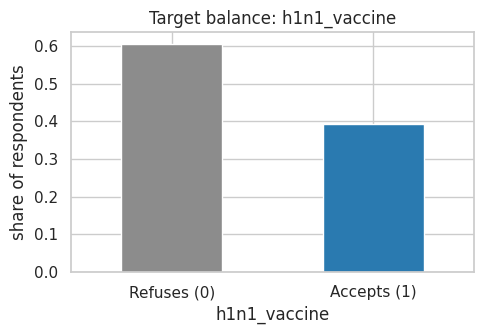

In [ ]:
print(train.dtypes.value_counts(), "\n")
print("duplicate respondent_ids:", train[ID].duplicated().sum())
print("\nTarget distribution:")
print(train[TARGET].value_counts().rename({0: "refuses (0)", 1: "accepts (1)"}))

fig, ax = plt.subplots(figsize=(5, 3.5))
train[TARGET].value_counts(normalize=True).sort_index().plot.bar(ax=ax, color=["#8c8c8c", "#2a7ab0"])
ax.set_xticklabels(["Refuses (0)", "Accepts (1)"], rotation=0)
ax.set_ylabel("share of respondents"); ax.set_title("Target balance: h1n1_vaccine")
plt.tight_layout(); plt.show()

,train %,test %
employment_sector,49.7,50.6
health_insurance,40.5,41.7
income_poverty,15.0,16.8
doctor_recc_h1n1,6.7,7.3
rent_or_own,6.6,8.0
employment_status,4.9,5.8
marital_status,4.8,5.7
education,4.7,5.7
child_under_6_months,2.8,3.3
health_worker,2.8,3.1


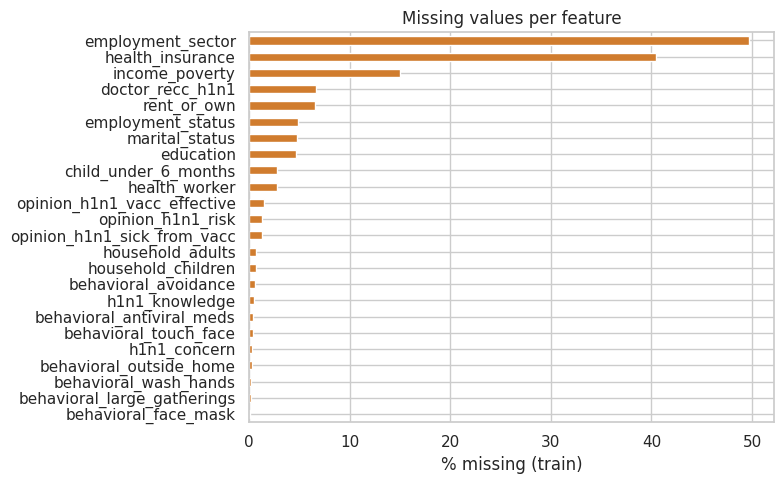

In [ ]:
# Missing values: which columns, how much, and in train vs test
miss = pd.DataFrame({"train %": train.isna().mean() * 100,
                     "test %": test.isna().mean().reindex(train.columns) * 100}).round(1)
miss = miss[miss["train %"] > 0].sort_values("train %", ascending=False)
display(miss)

fig, ax = plt.subplots(figsize=(8, 5))
miss["train %"].plot.barh(ax=ax, color="#d07c2e")
ax.invert_yaxis(); ax.set_xlabel("% missing (train)"); ax.set_title("Missing values per feature")
plt.tight_layout(); plt.show()

**Missingness may itself be informative** (e.g. `employment_sector` is empty for people who are not employed, `health_insurance` was not asked to everyone). Below we check whether the acceptance rate differs for missing vs non-missing rows — if it does, we keep "missing" as its own category rather than imputing it away.

In [ ]:
rows = []
for c in miss.index:
    rows.append({"feature": c,
                 "accept rate | missing": train.loc[train[c].isna(), TARGET].mean(),
                 "accept rate | present": train.loc[train[c].notna(), TARGET].mean()})
pd.DataFrame(rows).set_index("feature").round(3)

,accept rate | missing,accept rate | present
feature,,
employment_sector,0.385,0.403
health_insurance,0.236,0.502
income_poverty,0.365,0.399
doctor_recc_h1n1,0.182,0.409
rent_or_own,0.352,0.397
employment_status,0.353,0.396
marital_status,0.345,0.396
education,0.321,0.398
child_under_6_months,0.343,0.395


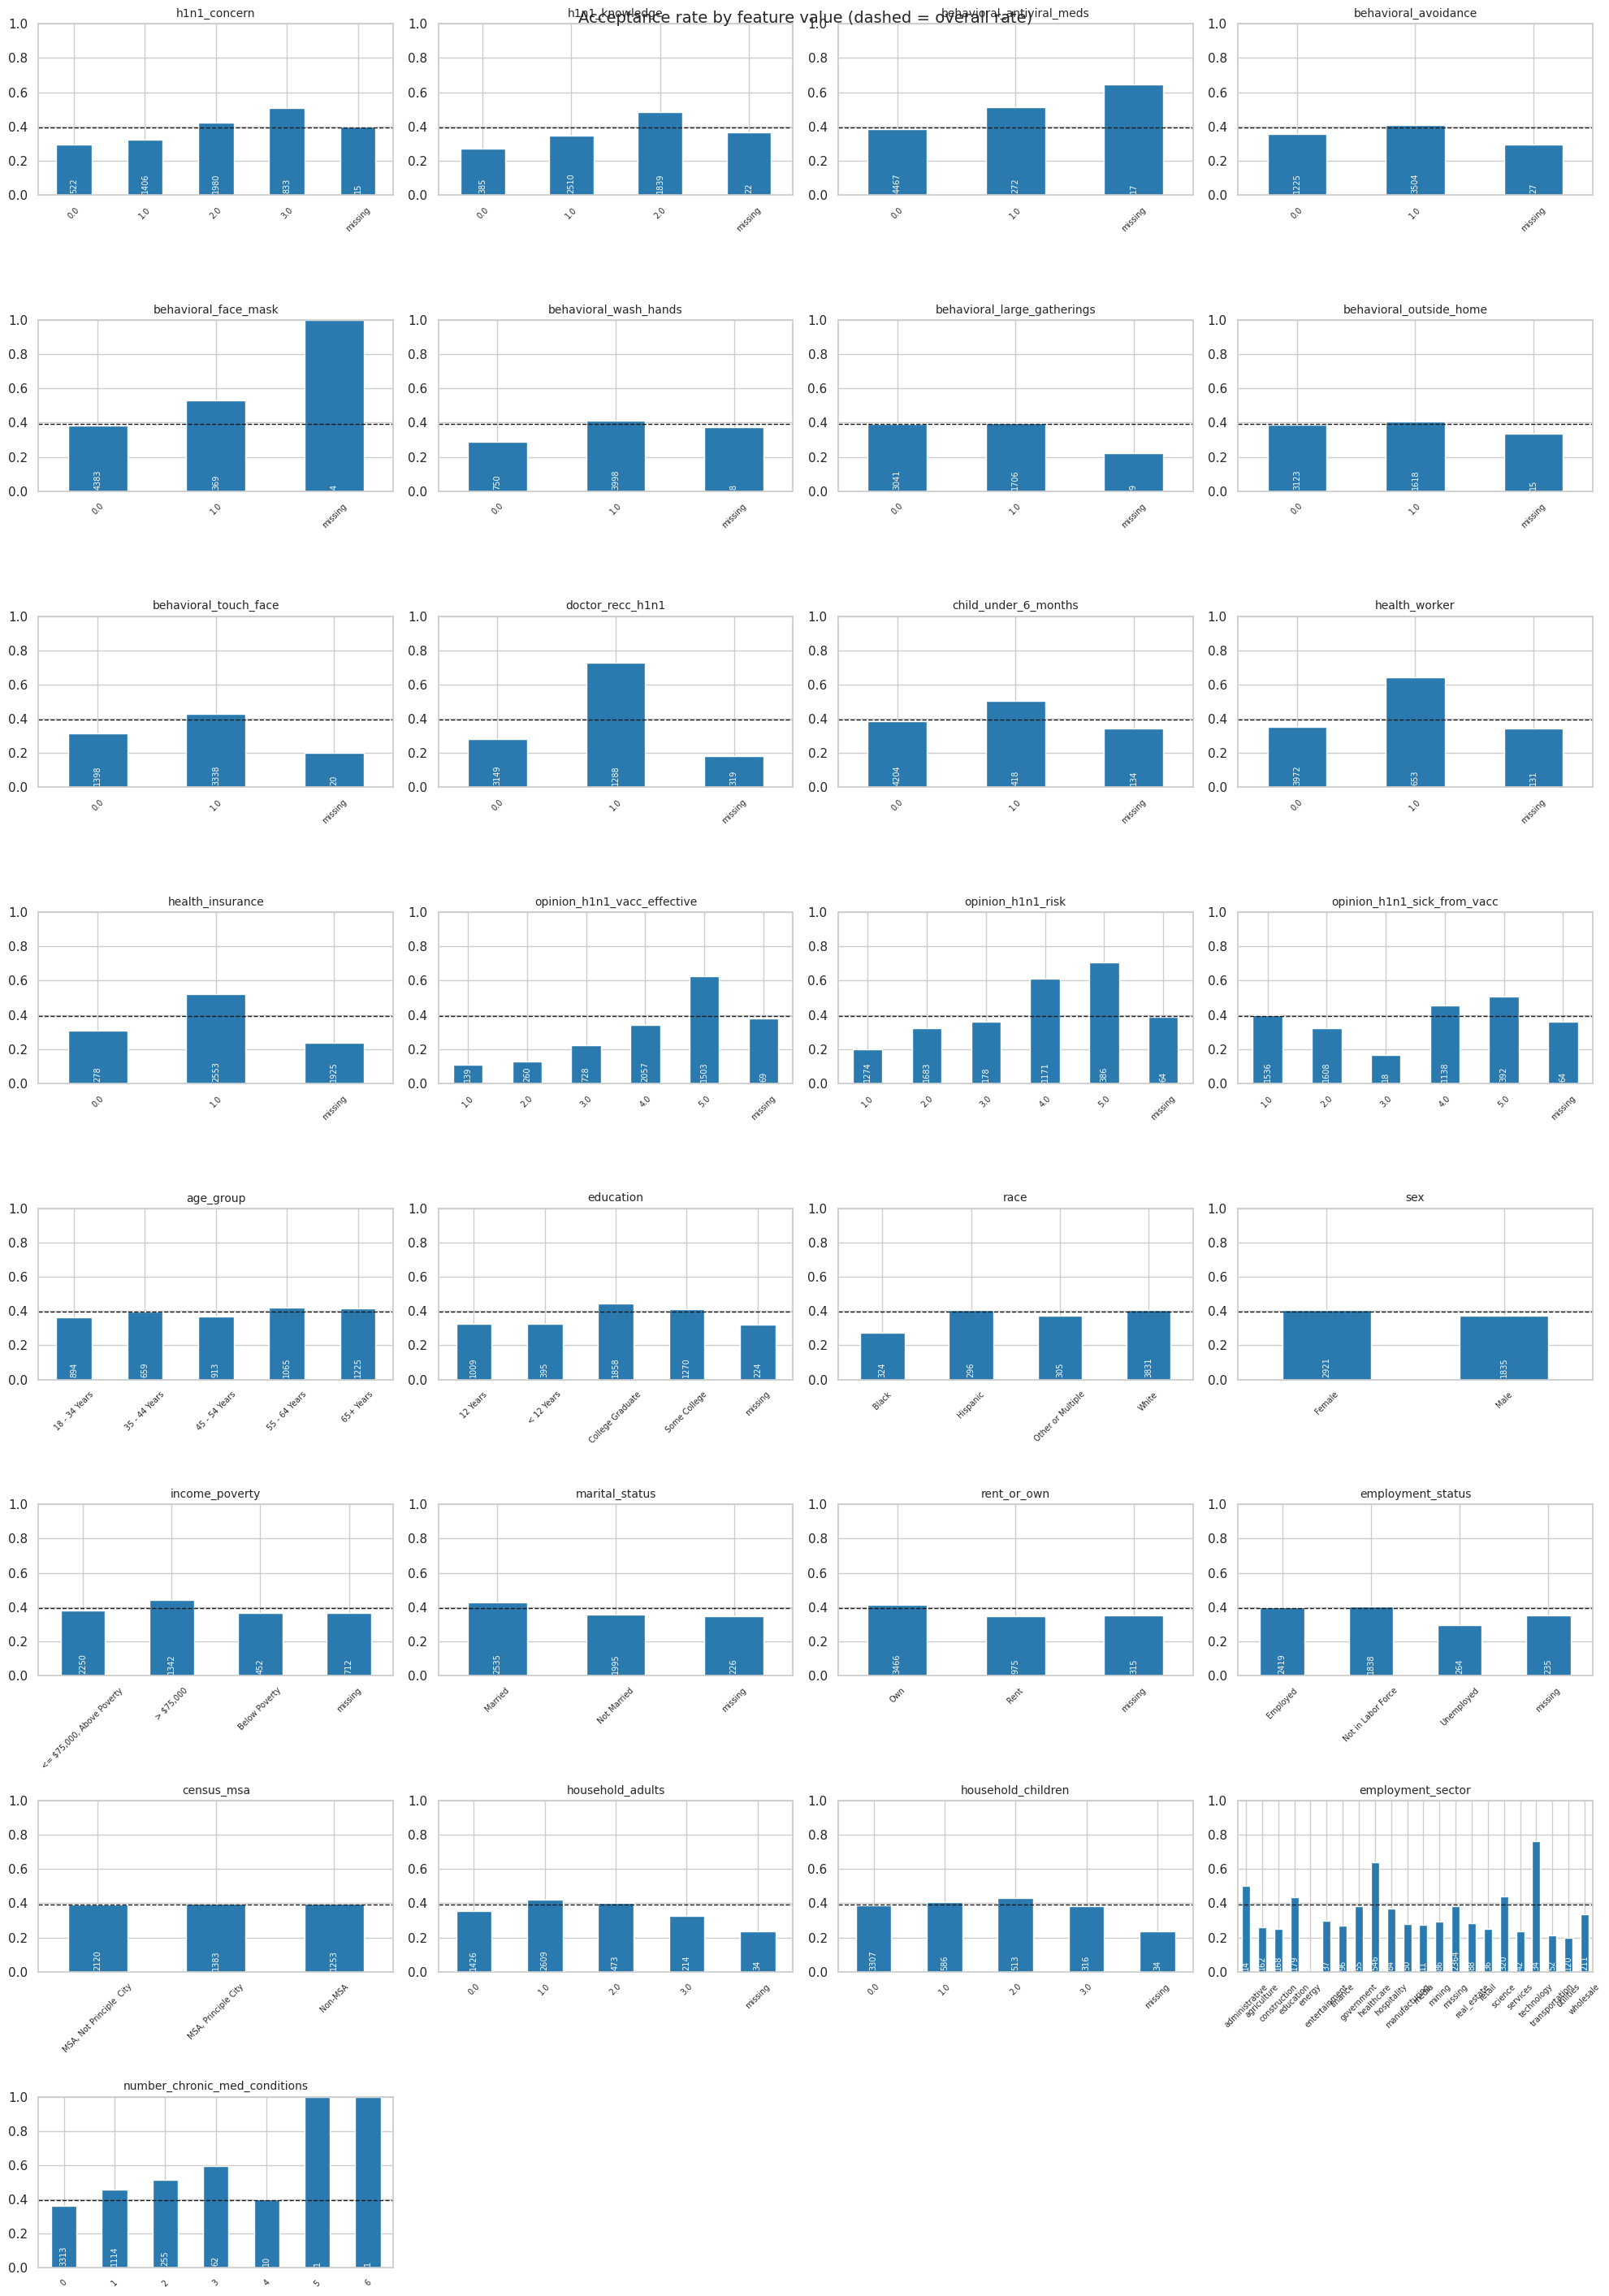

In [ ]:
# Acceptance rate by every feature (bar = share who accepted, n shown on bars)
features = [c for c in train.columns if c not in (ID, TARGET)]
ncols = 4
nrows = int(np.ceil(len(features) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(20, 3.6 * nrows))
for ax, c in zip(axes.ravel(), features):
    g = train.assign(**{c: train[c].fillna("missing").astype(str)}).groupby(c)[TARGET].agg(["mean", "size"])
    g["mean"].plot.bar(ax=ax, color="#2a7ab0")
    for i, n in enumerate(g["size"]):
        ax.text(i, 0.02, n, ha="center", fontsize=7, color="white", rotation=90)
    ax.axhline(train[TARGET].mean(), ls="--", color="k", lw=1)
    ax.set_title(c, fontsize=10); ax.set_xlabel(""); ax.set_ylim(0, 1)
    ax.tick_params(axis="x", labelsize=7, rotation=45)
for ax in axes.ravel()[len(features):]:
    ax.axis("off")
fig.suptitle("Acceptance rate by feature value (dashed = overall rate)", fontsize=14)
plt.tight_layout(); plt.show()

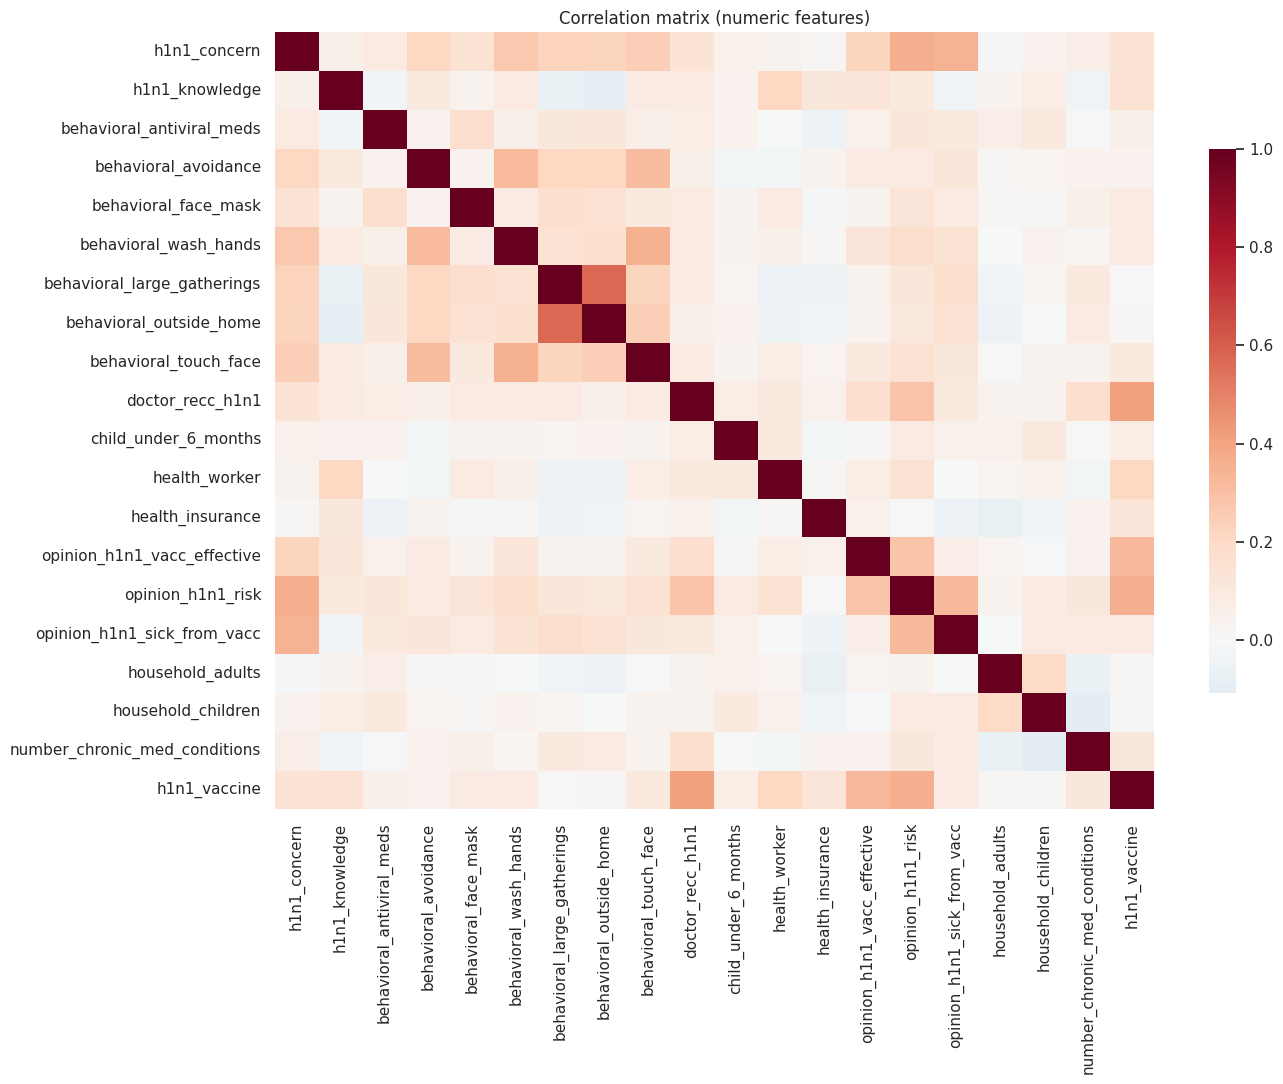

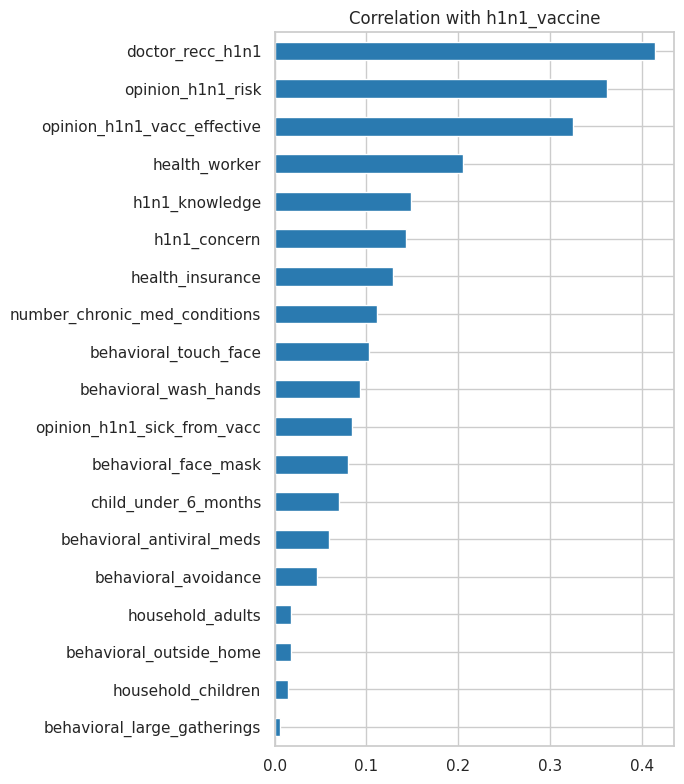

In [ ]:
# Correlation of numeric features with the target and with each other
num = train.select_dtypes("number").drop(columns=[ID])
corr = num.corr()
fig, ax = plt.subplots(figsize=(14, 11))
sns.heatmap(corr, cmap="RdBu_r", center=0, ax=ax, cbar_kws={"shrink": .7})
ax.set_title("Correlation matrix (numeric features)")
plt.tight_layout(); plt.show()

corr[TARGET].drop(TARGET).sort_values().plot.barh(figsize=(7, 8), color="#2a7ab0",
                                                  title="Correlation with h1n1_vaccine")
plt.tight_layout(); plt.show()

## 3. Task-specific metric: total cost to the town

**Rules from the brief:** everyone is infected (100%); anyone who wants a vaccine must get one, otherwise the town pays them the vaccine cost ($500); vaccines sent but refused are wasted; each hospitalisation costs $25,000.

| prediction | truth | cost |
|---|---|---|
| send (1) | accepts (1) | 500 + p_vacc × 25,000 |
| send (1) | refuses (0) | 500 (wasted) + p_unvacc × 25,000 |
| don't send (0) | wanted it (1) | 500 (paid instead) + p_unvacc × 25,000 |
| don't send (0) | refuses (0) | p_unvacc × 25,000 |

**Assumption to confirm with the tutor:** someone who is paid instead of receiving a vaccine stays unvaccinated.

### Hospitalisation probabilities (estimated with generative AI, as instructed)
* About **0.45 %** of 2009 H1N1 cases were hospitalised in the US, similar for 18–64 and 65+ (CDC estimates) → age is given little weight.
* Chronic medical conditions raise the risk several-fold → relative risk **1× / 4× / 6× / 8×** for 0 / 1 / 2 / 3+ conditions, rescaled so the town average stays at 0.45 %.
* Vaccine effectiveness against hospitalisation ≈ **60 %** (tested 40–80 % in section 7).

*Record here which AIs/people were asked and what they answered, to show the estimate is robust.*

### Decision rule
Sending a vaccine to person *i* pays off when the expected saving beats the expected waste:

P(accept) × (p_unvacc − p_vacc) × 25,000 > (1 − P(accept)) × 500

so each person gets their own threshold, lower for higher-risk people.

In [ ]:
VACC_COST, HOSP_COST = 500, 25_000
POP_HOSP_RATE = 0.0045                 # CDC: ~0.45% of 2009 H1N1 cases hospitalised
RR = {0: 1.0, 1: 4.0, 2: 6.0, 3: 8.0}  # relative risk by number of chronic conditions (3 = 3+)
VE = 0.60                              # vaccine effectiveness against hospitalisation


def risk_multiplier(n_chronic, rr=RR):
    n = pd.Series(n_chronic).fillna(0).clip(upper=3).astype(int)
    return n.map(rr).to_numpy()


# rescale so the average risk across the training population equals POP_HOSP_RATE
BASE_P = POP_HOSP_RATE / risk_multiplier(train["number_chronic_med_conditions"]).mean()


def hosp_probs(n_chronic, ve=VE, rr=RR, base_p=None):
    """Return (p_unvaccinated, p_vaccinated) hospitalisation probability per person."""
    if base_p is None:
        base_p = POP_HOSP_RATE / risk_multiplier(train["number_chronic_med_conditions"], rr).mean()
    p_u = base_p * risk_multiplier(n_chronic, rr)
    return p_u, p_u * (1 - ve)


def total_cost(y_true, send, n_chronic, **kw):
    """Total money spent by the town (lower is better)."""
    y_true, send = np.asarray(y_true).astype(int), np.asarray(send).astype(int)
    p_u, p_v = hosp_probs(n_chronic, **kw)
    vaccine = VACC_COST * ((send == 1) | (y_true == 1))          # sent, or paid instead
    protected = (send == 1) & (y_true == 1)
    hospital = HOSP_COST * np.where(protected, p_v, p_u)
    return float((vaccine + hospital).sum())


def cost_decision(p_accept, n_chronic, **kw):
    """Send a vaccine when expected saving > expected waste."""
    p_u, p_v = hosp_probs(n_chronic, **kw)
    saving = (p_u - p_v) * HOSP_COST
    return (np.asarray(p_accept) * saving > (1 - np.asarray(p_accept)) * VACC_COST).astype(int)


# the per-group thresholds implied by these assumptions
tab = pd.DataFrame({"n_chronic": [0, 1, 2, 3]})
tab["P(hosp) unvaccinated %"] = hosp_probs(tab.n_chronic)[0] * 100
tab["saving per protected person $"] = (hosp_probs(tab.n_chronic)[0] - hosp_probs(tab.n_chronic)[1]) * HOSP_COST
tab["send if P(accept) >"] = VACC_COST / (VACC_COST + tab["saving per protected person $"])
tab.round(3)

,n_chronic,P(hosp) unvaccinated %,saving per protected person $,send if P(accept) >
0,0,0.216,32.457,0.939
1,1,0.866,129.827,0.794
2,2,1.298,194.741,0.720
3,3,1.731,259.654,0.658


In [ ]:
# Reference points on the training data
y, nch = train[TARGET].to_numpy(), train["number_chronic_med_conditions"]
baselines = {
    "send nobody": total_cost(y, np.zeros_like(y), nch),
    "send everyone": total_cost(y, np.ones_like(y), nch),
    "perfect predictions": total_cost(y, y, nch),
}
base_df = pd.Series(baselines).to_frame("total cost $")
base_df["per person $"] = base_df["total cost $"] / len(y)
display(base_df.round(0))
print("Maximum possible saving vs 'send nobody':",
      round(baselines["send nobody"] - baselines["perfect predictions"]), "$")

,total cost $,per person $
send nobody,1472050.0,310.0
send everyone,2771733.0,583.0
perfect predictions,1330733.0,280.0


Maximum possible saving vs 'send nobody': 141317 $


## 4. Pre-processing

* **Ordinal text features** (`age_group`, `education`, `income_poverty`) → ordered integer codes; missing → imputed with the most frequent value plus a missing-indicator.
* **Nominal text features** (`race`, `sex`, `marital_status`, `rent_or_own`, `employment_status`, `census_msa`, `employment_sector`) → one-hot, with **"missing" kept as its own category**.
* **Numeric / binary / Likert features** → median imputation + missing-indicator columns; standardised for logistic regression.

In [ ]:
ORDINAL = {
    "age_group": ["18 - 34 Years", "35 - 44 Years", "45 - 54 Years", "55 - 64 Years", "65+ Years"],
    "education": ["< 12 Years", "12 Years", "Some College", "College Graduate"],
    "income_poverty": ["Below Poverty", "<= $75,000, Above Poverty", "> $75,000"],
}
for c, levels in ORDINAL.items():
    unknown = set(train[c].dropna()) - set(levels)
    assert not unknown, f"unexpected levels in {c}: {unknown}"

cat_cols = [c for c in train.columns if not pd.api.types.is_numeric_dtype(train[c]) and c not in ORDINAL]
ord_cols = list(ORDINAL)
num_cols = [c for c in train.columns if c not in cat_cols + ord_cols + [ID, TARGET]]
print("nominal:", cat_cols, "\nordinal:", ord_cols, "\nnumeric:", len(num_cols), "columns")


def make_preprocessor(scale=True):
    num_steps = [("impute", SimpleImputer(strategy="median", add_indicator=True))]
    if scale:
        num_steps.append(("scale", StandardScaler()))
    # encode the ordered levels as 0,1,2,... (NaN stays NaN), then impute + add missing-indicator
    ord_pipe = Pipeline([("encode", OrdinalEncoder(categories=[ORDINAL[c] for c in ord_cols],
                                                   handle_unknown="use_encoded_value", unknown_value=np.nan)),
                         ("impute", SimpleImputer(strategy="most_frequent", add_indicator=True))])
    if scale:
        ord_pipe.steps.append(("scale", StandardScaler()))
    cat_pipe = Pipeline([("fill", SimpleImputer(strategy="constant", fill_value="missing")),
                         ("onehot", OneHotEncoder(handle_unknown="ignore"))])
    return ColumnTransformer([("num", Pipeline(num_steps), num_cols),
                              ("ord", ord_pipe, ord_cols),
                              ("cat", cat_pipe, cat_cols)])


X, X_test = train.drop(columns=[ID, TARGET]), test.drop(columns=[ID])
n_feat = make_preprocessor().fit_transform(X).shape[1]
print("features after pre-processing:", n_feat)

nominal: ['race', 'sex', 'marital_status', 'rent_or_own', 'employment_status', 'census_msa', 'employment_sector'] 
ordinal: ['age_group', 'education', 'income_poverty'] 
numeric: 19 columns
features after pre-processing: 83


## 5. Modelling, tuning & cross-validation

Because the decision rule uses the **predicted probability**, models are tuned on **log-loss** (a probability-quality score), not accuracy. Each model is evaluated with 5-fold stratified cross-validation using out-of-fold predictions, so every training row gets a prediction from a model that never saw it.

In [ ]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

candidates = {
    "LogReg": (Pipeline([("prep", make_preprocessor(True)),
                         ("clf", LogisticRegression(max_iter=2000))]),
               {"clf__C": np.logspace(-3, 1, 20)}),
    "RandomForest": (Pipeline([("prep", make_preprocessor(False)),
                               ("clf", RandomForestClassifier(n_estimators=400, random_state=SEED, n_jobs=-1))]),
                     {"clf__max_depth": [6, 8, 10, 14, None], "clf__min_samples_leaf": [1, 3, 5, 10, 20],
                      "clf__max_features": ["sqrt", 0.3, 0.5]}),
    "HistGB": (Pipeline([("prep", make_preprocessor(False)),
                         ("clf", HistGradientBoostingClassifier(random_state=SEED))]),
               {"clf__learning_rate": [0.02, 0.05, 0.1], "clf__max_depth": [2, 3, 4, None],
                "clf__max_iter": [100, 200, 400], "clf__min_samples_leaf": [10, 20, 50],
                "clf__l2_regularization": [0, 0.1, 1.0]}),
}
if HAS_XGB:
    candidates["XGBoost"] = (Pipeline([("prep", make_preprocessor(False)),
                                       ("clf", XGBClassifier(eval_metric="logloss", random_state=SEED, n_jobs=-1))]),
                             {"clf__n_estimators": [200, 400, 600], "clf__learning_rate": [0.02, 0.05, 0.1],
                              "clf__max_depth": [2, 3, 4, 5], "clf__subsample": [0.7, 0.9, 1.0],
                              "clf__colsample_bytree": [0.5, 0.7, 1.0], "clf__min_child_weight": [1, 5, 10]})

best_models = {}
for name, (pipe, grid) in candidates.items():
    search = RandomizedSearchCV(pipe, grid, n_iter=15, scoring="neg_log_loss", cv=cv,
                                random_state=SEED, n_jobs=-1)
    search.fit(X, y)
    best_models[name] = search.best_estimator_
    print(f"{name:13s} best CV log-loss = {-search.best_score_:.4f} | {search.best_params_}")

LogReg        best CV log-loss = 0.4646 | {'clf__C': np.float64(0.04832930238571752)}
RandomForest  best CV log-loss = 0.4624 | {'clf__min_samples_leaf': 1, 'clf__max_features': 0.3, 'clf__max_depth': 10}
HistGB        best CV log-loss = 0.4592 | {'clf__min_samples_leaf': 10, 'clf__max_iter': 400, 'clf__max_depth': 2, 'clf__learning_rate': 0.1, 'clf__l2_regularization': 0.1}
XGBoost       best CV log-loss = 0.4556 | {'clf__subsample': 0.9, 'clf__n_estimators': 600, 'clf__min_child_weight': 5, 'clf__max_depth': 4, 'clf__learning_rate': 0.02, 'clf__colsample_bytree': 0.5}


In [ ]:
# Calibrated versions of the tree models (isotonic calibration inside each fold)
for name in [n for n in list(best_models) if n != "LogReg"]:
    best_models[name + "+calib"] = CalibratedClassifierCV(best_models[name], method="isotonic", cv=3)

# Out-of-fold probabilities for every model
oof = {}
for name, model in best_models.items():
    oof[name] = cross_val_predict(model, X, y, cv=cv, method="predict_proba", n_jobs=-1)[:, 1]
    print(f"{name:20s} AUC={roc_auc_score(y, oof[name]):.4f}  log-loss={log_loss(y, oof[name]):.4f}  "
          f"Brier={brier_score_loss(y, oof[name]):.4f}")

LogReg               AUC=0.8494  log-loss=0.4645  Brier=0.1500
RandomForest         AUC=0.8519  log-loss=0.4624  Brier=0.1494
HistGB               AUC=0.8528  log-loss=0.4592  Brier=0.1480
XGBoost              AUC=0.8545  log-loss=0.4556  Brier=0.1470
RandomForest+calib   AUC=0.8509  log-loss=0.4614  Brier=0.1490
HistGB+calib         AUC=0.8519  log-loss=0.4657  Brier=0.1482
XGBoost+calib        AUC=0.8534  log-loss=0.4635  Brier=0.1474


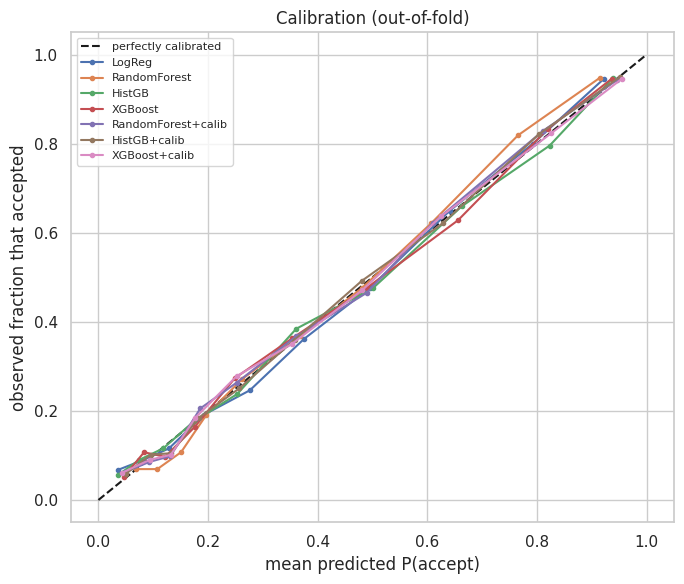

In [ ]:
# Calibration curves: are predicted probabilities trustworthy?
fig, ax = plt.subplots(figsize=(7, 6))
ax.plot([0, 1], [0, 1], "k--", label="perfectly calibrated")
for name, p in oof.items():
    frac, mean_pred = calibration_curve(y, p, n_bins=10, strategy="quantile")
    ax.plot(mean_pred, frac, marker="o", ms=3, label=name)
ax.set_xlabel("mean predicted P(accept)"); ax.set_ylabel("observed fraction that accepted")
ax.set_title("Calibration (out-of-fold)"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

## 6. Cost-based decisions & model comparison

In [ ]:
rows = []
fold_costs = {}
for name, p in oof.items():
    send = cost_decision(p, nch)
    per_fold = []
    for _, val_idx in cv.split(X, y):
        per_fold.append(total_cost(y[val_idx], send[val_idx], nch.iloc[val_idx]) / len(val_idx))
    fold_costs[name] = per_fold
    rows.append({"model": name, "total cost $": total_cost(y, send, nch),
                 "cost per person $": np.mean(per_fold), "std across folds $": np.std(per_fold),
                 "vaccines sent": int(send.sum()),
                 "sent & accepted": int((send & (y == 1)).sum()),
                 "wasted": int((send & (y == 0)).sum())})

# baselines in the same table
for name, send in [("BASELINE send nobody", np.zeros_like(y)), ("BASELINE send everyone", np.ones_like(y)),
                   ("BASELINE perfect", y)]:
    rows.append({"model": name, "total cost $": total_cost(y, send, nch),
                 "cost per person $": total_cost(y, send, nch) / len(y),
                 "vaccines sent": int(send.sum())})

results = pd.DataFrame(rows).set_index("model").sort_values("total cost $")
results["saving vs send nobody $"] = baselines["send nobody"] - results["total cost $"]
display(results.round(2))

,total cost $,cost per person $,std across folds $,vaccines sent,sent & accepted,wasted,saving vs send nobody $
model,,,,,,,
BASELINE perfect,1330733.18,279.80,NaN,1874,NaN,NaN,141316.82
RandomForest+calib,1432600.67,301.22,3.19,505,474.0,31.0,39449.33
RandomForest,1435546.42,301.84,3.68,385,362.0,23.0,36503.58
XGBoost+calib,1436231.33,301.98,3.92,549,506.0,43.0,35818.67
HistGB+calib,1436327.87,302.00,3.41,521,483.0,38.0,35722.13
XGBoost,1437373.48,302.22,4.46,478,437.0,41.0,34676.52
HistGB,1438886.62,302.54,4.18,492,447.0,45.0,33163.38
LogReg,1441501.65,303.09,3.85,416,377.0,39.0,30548.35
BASELINE send nobody,1472050.00,309.51,NaN,0,NaN,NaN,0.00


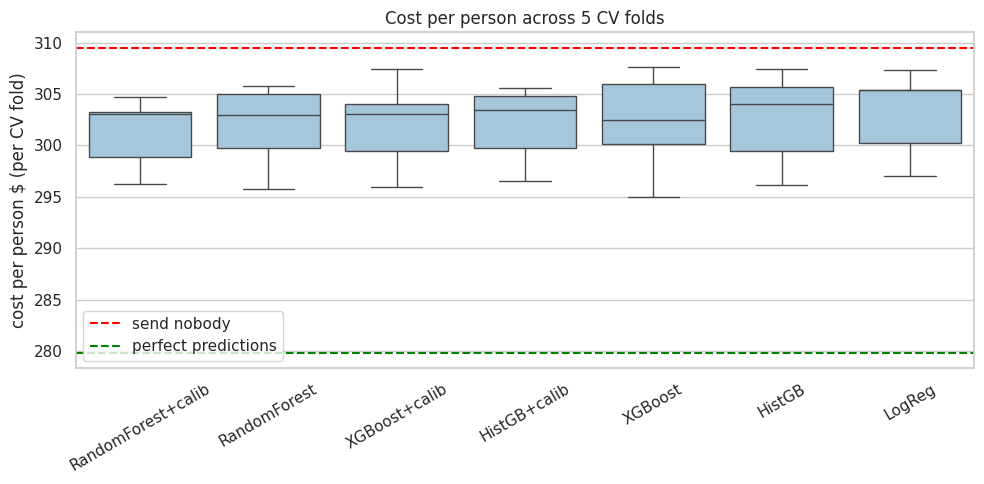

In [ ]:
fig, ax = plt.subplots(figsize=(10, 5))
plot_df = pd.DataFrame(fold_costs)
plot_df = plot_df[plot_df.mean().sort_values().index]
sns.boxplot(data=plot_df, ax=ax, color="#9ecae1")
ax.axhline(baselines["send nobody"] / len(y), color="red", ls="--", label="send nobody")
ax.axhline(baselines["perfect predictions"] / len(y), color="green", ls="--", label="perfect predictions")
ax.set_ylabel("cost per person $ (per CV fold)"); ax.set_title("Cost per person across 5 CV folds")
ax.tick_params(axis="x", rotation=30); ax.legend()
plt.tight_layout(); plt.show()

## 7. Sensitivity analysis

The hospitalisation numbers are estimates. We re-score every model under different vaccine-effectiveness and relative-risk assumptions to check that the **ranking** of models is robust.

In [ ]:
scenarios = {
    "VE 40%": dict(ve=0.4), "VE 60% (base)": dict(ve=0.6), "VE 80%": dict(ve=0.8),
    "RR low 1/2/3/4": dict(rr={0: 1, 1: 2, 2: 3, 3: 4}),
    "RR high 1/5/8/12": dict(rr={0: 1, 1: 5, 2: 8, 3: 12}),
}
sens = {}
for sc, kw in scenarios.items():
    nobody = total_cost(y, np.zeros_like(y), nch, **kw)
    sens[sc] = {name: nobody - total_cost(y, cost_decision(p, nch, **kw), nch, **kw) for name, p in oof.items()}
sens = pd.DataFrame(sens)
print("Saving vs 'send nobody' ($) under each scenario:")
display(sens.round(0))
print("Rank of each model (1 = lowest cost):")
display(sens.rank(ascending=False).astype(int))

Saving vs 'send nobody' ($) under each scenario:


,VE 40%,VE 60% (base),VE 80%,RR low 1/2/3/4,RR high 1/5/8/12
LogReg,18043.0,30548.0,54017.0,23012.0,37063.0
RandomForest,18232.0,36504.0,55506.0,23684.0,38513.0
HistGB,17618.0,33163.0,55143.0,27139.0,37292.0
XGBoost,20442.0,34677.0,56753.0,26812.0,39955.0
RandomForest+calib,20397.0,39449.0,58262.0,29882.0,43020.0
HistGB+calib,17122.0,35722.0,57705.0,26291.0,39368.0
XGBoost+calib,18022.0,35819.0,55912.0,29362.0,38390.0


Rank of each model (1 = lowest cost):


,VE 40%,VE 60% (base),VE 80%,RR low 1/2/3/4,RR high 1/5/8/12
LogReg,4,7,7,7,7
RandomForest,3,2,5,6,4
HistGB,6,6,6,3,6
XGBoost,1,5,3,4,2
RandomForest+calib,2,1,1,1,1
HistGB+calib,7,4,2,5,3
XGBoost+calib,5,3,4,2,5


## 8. Final predictions — top 5 submissions

Models are ranked by **cross-validated total cost** (section 6). Each is refitted on the full training set, predicts P(accept) for the test set, and the cost decision rule turns that into 0/1.

In [ ]:
ranking = results.loc[[m for m in results.index if not m.startswith("BASELINE")]].index[:5].tolist()
print("Submission order:", ranking)

nch_test = test["number_chronic_med_conditions"]
for order, name in enumerate(ranking, start=1):
    model = best_models[name].fit(X, y)
    p_test = model.predict_proba(X_test)[:, 1]
    send = cost_decision(p_test, nch_test)
    sub = pd.DataFrame({ID: test[ID], TARGET: send})
    assert len(sub) == len(example_sub) and sub[ID].equals(example_sub[ID])
    fname = f"challenge_submission_group_{GROUP}_order_{order}.csv"
    sub.to_csv(fname, index=False)
    print(f"{fname}: {name:20s} vaccines sent = {send.sum()} / {len(send)}")

Submission order: ['RandomForest+calib', 'RandomForest', 'XGBoost+calib', 'HistGB+calib', 'XGBoost']
challenge_submission_group_0_order_1.csv: RandomForest+calib   vaccines sent = 469 / 4749
challenge_submission_group_0_order_2.csv: RandomForest         vaccines sent = 374 / 4749
challenge_submission_group_0_order_3.csv: XGBoost+calib        vaccines sent = 539 / 4749
challenge_submission_group_0_order_4.csv: HistGB+calib         vaccines sent = 531 / 4749
challenge_submission_group_0_order_5.csv: XGBoost              vaccines sent = 491 / 4749


## 9. Explainable AI

Which features drive the predicted probability of accepting the vaccine?

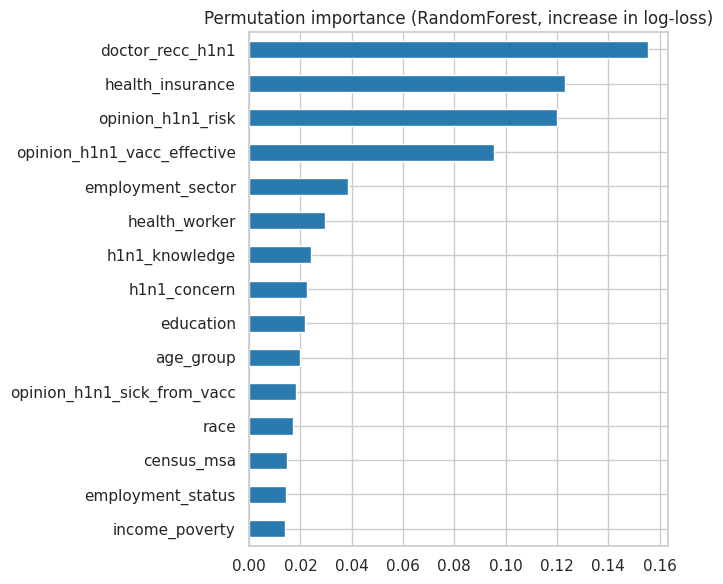

In [ ]:
best_name = ranking[0]
base_name = best_name.replace("+calib", "")
model = best_models[base_name].fit(X, y)
prep, clf = model.named_steps["prep"], model.named_steps["clf"]
feat_names = prep.get_feature_names_out()

from sklearn.inspection import permutation_importance
pi = permutation_importance(model, X, y, scoring="neg_log_loss", n_repeats=5, random_state=SEED, n_jobs=-1)
imp = pd.Series(pi.importances_mean, index=X.columns).sort_values()
imp.tail(15).plot.barh(figsize=(7, 6), color="#2a7ab0",
                       title=f"Permutation importance ({base_name}, increase in log-loss)")
plt.tight_layout(); plt.show()

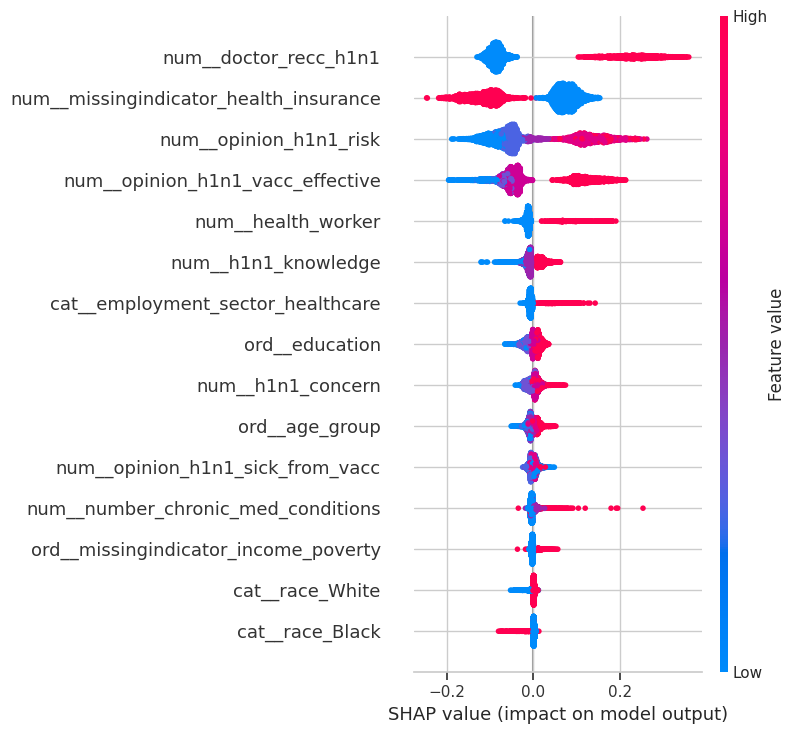

In [ ]:
# SHAP values (tree models) — direction and size of each feature's effect
try:
    import shap
    Xt = prep.transform(X)
    Xt = Xt.toarray() if hasattr(Xt, "toarray") else Xt
    if base_name == "LogReg":
        explainer = shap.LinearExplainer(clf, Xt)
    else:
        explainer = shap.TreeExplainer(clf)
    sv = explainer.shap_values(Xt)
    sv = sv[1] if isinstance(sv, list) else sv
    if sv.ndim == 3:
        sv = sv[:, :, 1]
    shap.summary_plot(sv, pd.DataFrame(Xt, columns=feat_names), max_display=15)
except Exception as e:
    print("SHAP not available:", e, "-> run  !pip install shap  and re-run this cell")